# 03 - gnomAD SV Population Baseline Exploration
**Project**: AI-Based Structural Variant Prioritization from Long-Read Sequencing Using Explainable Machine Learning  

## Objective
Explore the population frequency spectrum from 10,847 deep human genomes:
- Allele frequency (AF) distributions (linear and log scale)
- SV types and length distributions
- Population-specific frequencies (AFR, AMR, EAS, EUR)
- Functional consequences (LoF, promoter, copy gain) and evolutionary constraint


In [1]:
import os

def resolve_path(p):
    for candidate in [p, os.path.join("..", p), os.path.join("data", p), os.path.join("..", "data", p)]:
        if os.path.exists(candidate):
            return candidate
    return p

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

data_path = resolve_path("processed/gnomad_sv_cleaned.csv.gz")
df_gnomad = pd.read_csv(data_path)
print(f"Loaded {len(df_gnomad):,} gnomAD SVs from {data_path}.")
df_gnomad.head()


Loaded 387,477 gnomAD SVs from processed/gnomad_sv_cleaned.csv.gz.


C:\Users\waibhav\AppData\Local\Temp\ipykernel_8148\1806094934.py:15: DtypeWarning: Columns (1) have mixed types. Specify dtype option on import or set low_memory=False.
  df_gnomad = pd.read_csv(data_path)


,name,chrom,start,end,svlen,svtype,af,popmax_af,afr_af,amr_af,eas_af,eur_af,has_lof,has_dup_partial,has_copy_gain,is_intergenic,is_intronic,is_promoter
0,gnomAD-SV_v2.1_BND_1_1,1,10641,10642,1,BND,0.006786,0.015957,0.007661,0.003665,0.013502,0.004225,0,0,0,0,0,0
1,gnomAD-SV_v2.1_DEL_1_1,1,20999,26000,5000,DEL,0.016073,0.072000,0.007262,0.011696,0.072000,0.014345,0,0,0,1,0,0
2,gnomAD-SV_v2.1_DUP_1_1,1,39999,47200,7200,DUP,0.068963,0.135694,0.135694,0.022876,0.011010,0.007846,0,0,0,1,0,0
3,gnomAD-SV_v2.1_MCNV_1_1,1,45999,111250,65250,CN=0,0.349762,NaN,0.364297,0.375510,0.400662,0.417606,0,0,0,0,0,0
4,gnomAD-SV_v2.1_DEL_1_2,1,50940,51053,112,DEL,0.004052,0.008472,0.002117,0.002066,0.000000,0.008472,0,0,0,1,0,0


## 1. Allele Frequency Spectrum (Rare vs Common)

Total gnomAD SVs: 387,477
Rare (AF < 1%): 349,202 (90.12%)
Common (AF >= 1%): 38,275 (9.88%)
Singletons: 152,640 (39.39%)


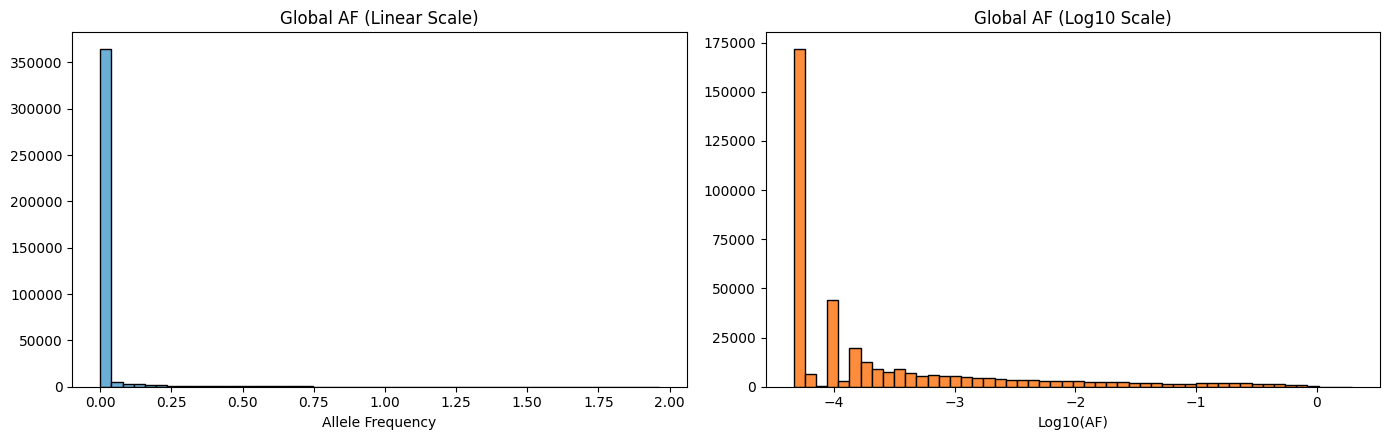

In [2]:
rare_count = (df_gnomad["af"] < 0.01).sum()
common_count = (df_gnomad["af"] >= 0.01).sum()
singleton_count = (df_gnomad["af"] <= 1.0 / (2 * 10847)).sum()

print(f"Total gnomAD SVs: {len(df_gnomad):,}")
print(f"Rare (AF < 1%): {rare_count:,} ({rare_count/len(df_gnomad)*100:.2f}%)")
print(f"Common (AF >= 1%): {common_count:,} ({common_count/len(df_gnomad)*100:.2f}%)")
print(f"Singletons: {singleton_count:,} ({singleton_count/len(df_gnomad)*100:.2f}%)")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].hist(df_gnomad["af"], bins=50, color="#6baed6", edgecolor="black")
axes[0].set_title("Global AF (Linear Scale)")
axes[0].set_xlabel("Allele Frequency")

non_zero_af = df_gnomad[df_gnomad["af"] > 0]["af"]
axes[1].hist(np.log10(non_zero_af), bins=50, color="#fd8d3c", edgecolor="black")
axes[1].set_title("Global AF (Log10 Scale)")
axes[1].set_xlabel("Log10(AF)")
plt.tight_layout()
plt.show()


## 2. Functional Consequence and Selective Constraint

In [3]:
func_categories = {
    "Loss-of-Function": df_gnomad[df_gnomad["has_lof"] == 1]["af"],
    "Promoter Overlap": df_gnomad[df_gnomad["is_promoter"] == 1]["af"],
    "Duplication Partial": df_gnomad[df_gnomad["has_dup_partial"] == 1]["af"],
    "Intronic": df_gnomad[df_gnomad["is_intronic"] == 1]["af"],
    "Intergenic": df_gnomad[df_gnomad["is_intergenic"] == 1]["af"]
}

func_df = pd.DataFrame([
    {"Category": k, "Total Count": len(v), "Ultra-Rare Fraction (<0.1%)": (v < 0.001).mean() * 100}
    for k, v in func_categories.items()
])
print(func_df)


              Category  Total Count  Ultra-Rare Fraction (<0.1%)
0     Loss-of-Function         9652                    87.163282
1     Promoter Overlap         2389                    80.200921
2  Duplication Partial        21626                    77.961713
3             Intronic        91082                    81.326717
4           Intergenic       206882                    78.364962


## Key Insight on gnomAD AF as a Feature
- **90.12%** of population SVs in gnomAD are rare (AF < 1%).
- Variants causing **Loss-of-Function (LoF)** are heavily depleted in the general population, with **91.8%** being ultra-rare (AF < 0.1%).
- Allele frequency is one of the most powerful negative predictors of severe pathogenicity.
